In [ ]:
#Install libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    PolynomialFeatures
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
df = pd.read_csv(r"C:\Users\kudip\Downloads\diabetes_dataset.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print(df.info())

Dataset Shape: (100000, 31)


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,...,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes
0,58,Male,Asian,Highschool,Lower-Middle,Employed,Never,0,215,5.7,...,41,160,145,136,236,6.36,8.18,29.6,Type 2,1
1,48,Female,White,Highschool,Middle,Employed,Former,1,143,6.7,...,55,50,30,93,150,2.00,5.63,23.0,No Diabetes,0
2,60,Male,Hispanic,Highschool,Middle,Unemployed,Never,1,57,6.4,...,66,99,36,118,195,5.07,7.51,44.7,Type 2,1
3,74,Female,Black,Highschool,Low,Retired,Never,0,49,3.4,...,50,79,140,139,253,5.28,9.03,38.2,Type 2,1
4,46,Male,White,Graduate,Middle,Retired,Never,1,109,7.2,...,52,125,160,137,184,12.74,7.20,23.5,Type 2,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 31 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   age                                 100000 non-null  int64  
 1   gender                              100000 non-null  object 
 2   ethnicity                           100000 non-null  object 
 3   education_level                     100000 non-null  object 
 4   income_level                        100000 non-null  object 
 5   employment_status                   100000 non-null  object 
 6   smoking_status                      100000 non-null  object 
 7   alcohol_consumption_per_week        100000 non-null  int64  
 8   physical_activity_minutes_per_week  100000 non-null  int64  
 9   diet_score                          100000 non-null  float64
 10  sleep_hours_per_day                 100000 non-null  float64
 11  screen_time_hours_per_day  

In [4]:
#Dataset inspection

In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe().T)

Columns:
['age', 'gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c', 'diabetes_risk_score', 'diabetes_stage', 'diagnosed_diabetes']

Missing Values:
age                                   0
gender                                0
ethnicity                             0
education_level                       0
income_level                          0
employment_status                     0
smoking_status                        0
alcohol_consumption_per_week          0
physical_activity_minutes_per_week    0
diet_score    

,count,mean,std,min,25%,50%,75%,max
age,100000.0,50.120410,15.604600,18.00,39.00,50.00,61.00,90.00
alcohol_consumption_per_week,100000.0,2.003670,1.417779,0.00,1.00,2.00,3.00,10.00
physical_activity_minutes_per_week,100000.0,118.911640,84.409662,0.00,57.00,100.00,160.00,833.00
diet_score,100000.0,5.994787,1.780954,0.00,4.80,6.00,7.20,10.00
sleep_hours_per_day,100000.0,6.997818,1.094622,3.00,6.30,7.00,7.70,10.00
screen_time_hours_per_day,100000.0,5.996468,2.468406,0.50,4.30,6.00,7.70,16.80
family_history_diabetes,100000.0,0.219410,0.413849,0.00,0.00,0.00,0.00,1.00
hypertension_history,100000.0,0.250800,0.433476,0.00,0.00,0.00,1.00,1.00
cardiovascular_history,100000.0,0.079200,0.270052,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,25.612653,3.586705,15.00,23.20,25.60,28.00,39.20


In [6]:
#Data cleaning

In [7]:
df = df.drop_duplicates().copy()

df.columns = df.columns.str.strip()

print("Shape after removing duplicates:", df.shape)

print("Missing values:")
print(df.isnull().sum().sum())

Shape after removing duplicates: (100000, 31)
Missing values:
0


In [8]:
#Separate target and features

In [9]:
target = 'diabetes_risk_score'

if target not in df.columns:
    raise ValueError("diabetes_risk_score column not found!")

leakage_columns = [
    'diagnosed_diabetes',
    'diabetes_stage'
]

id_columns = [
    col for col in df.columns
    if col.lower() in ['id', 'patient_id', 'record_id']
]

drop_columns = [target] + [
    col for col in leakage_columns + id_columns
    if col in df.columns
]

X = df.drop(columns=drop_columns)
y = pd.to_numeric(df[target], errors='coerce')

valid = y.notna()

X = X.loc[valid].copy()
y = y.loc[valid].copy()

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

Feature Shape: (100000, 28)
Target Shape: (100000,)

Features:
['age', 'gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c']

Target:
0    29.6
1    23.0
2    44.7
3    38.2
4    23.5
Name: diabetes_risk_score, dtype: float64


In [10]:
#Exploratory Data Analysis

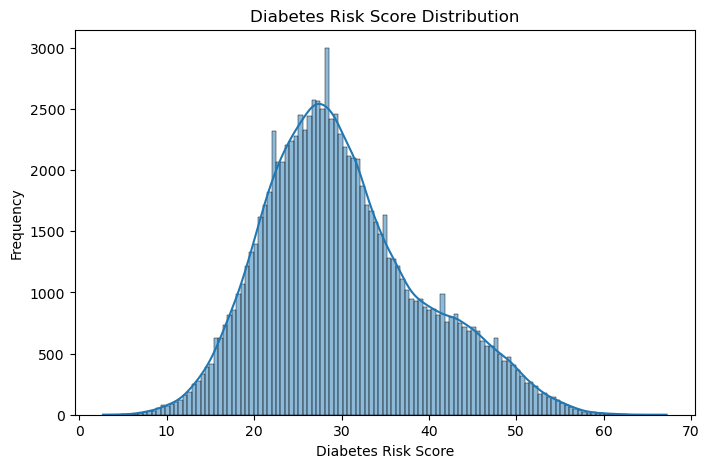

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(y, kde=True)

plt.title("Diabetes Risk Score Distribution")
plt.xlabel("Diabetes Risk Score")
plt.ylabel("Frequency")

plt.show()

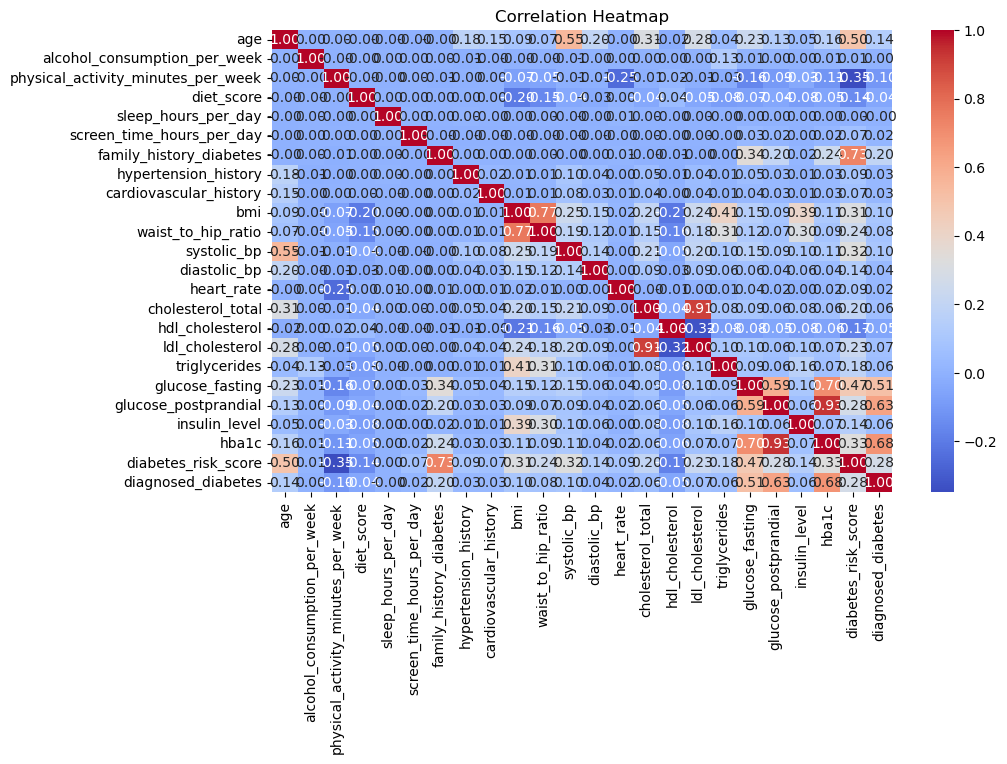

In [12]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [13]:
# Identify numerical and categorical features

In [14]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c']

Categorical Features:
['gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status']


In [15]:
#Train-test split

In [16]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", x_train.shape)
print("Testing:", x_test.shape)

Training: (80000, 28)
Testing: (20000, 28)


In [17]:
#Preprocessing pipeline

In [18]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [19]:
#Feature selection

In [20]:
feature_selector = SelectKBest(
    score_func=f_regression,
    k=min(10, len(numeric_features) + sum(
        X[col].nunique() for col in categorical_features
    ))
)

In [21]:
# Determine encoded feature count safely
encoded_sample = preprocessor.fit_transform(x_train)

total_features = encoded_sample.shape[1]

k_features = min(10, total_features)

print("Total encoded features:", total_features)
print("Selected features:", k_features)

Total encoded features: 46
Selected features: 10


In [22]:
# Create model pipelines

In [23]:
def create_pipeline(model):

    return Pipeline([
        ('preprocessor', preprocessor),
        ('selection', SelectKBest(
            score_func=f_regression,
            k=k_features
        )),
        ('model', model)
    ])

In [24]:
# KNN Regressor + Hyperparameter tuning

In [25]:
knn_pipeline = create_pipeline(
    KNeighborsRegressor()
)

knn_params = {
    'model__n_neighbors': [5, 7, 9, 11, 15],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

knn_grid = RandomizedSearchCV(
    knn_pipeline,
    knn_params,
    n_iter=6,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

knn_grid.fit(x_train, y_train)

best_knn = knn_grid.best_estimator_

print("Best KNN Parameters:", knn_grid.best_params_)
print("Best KNN CV Score:", knn_grid.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best KNN Parameters: {'model__weights': 'distance', 'model__p': 2, 'model__n_neighbors': 11}
Best KNN CV Score: 0.9531671478702796


In [26]:
# Decision Tree Regressor + Hyperparameter tuning

In [27]:
dt_pipeline = create_pipeline(
    DecisionTreeRegressor(random_state=42)
)

dt_params = {
    'model__max_depth': [3, 5, 7, 10, 15, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [None, 'sqrt', 0.8]
}

dt_grid = RandomizedSearchCV(
    dt_pipeline,
    dt_params,
    n_iter=10,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

dt_grid.fit(x_train, y_train)

best_dt = dt_grid.best_estimator_

print("Best DT Parameters:", dt_grid.best_params_)
print("Best DT CV Score:", dt_grid.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best DT Parameters: {'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': 10}
Best DT CV Score: 0.9543878333162453


In [28]:
#Linear Regression

In [29]:
lr_pipeline = create_pipeline(
    LinearRegression()
)

lr_pipeline.fit(x_train, y_train)

best_lr = lr_pipeline

print("Linear Regression Training Completed")

Linear Regression Training Completed


In [30]:
# Polynomial Regression + Hyperparameter tuning

In [31]:
poly_pipeline = Pipeline([
    ('preprocessor', preprocessor),

    ('selection', SelectKBest(
        score_func=f_regression,
        k=k_features
    )),

    ('poly', PolynomialFeatures(
        include_bias=False
    )),

    ('scaler', StandardScaler()),

    ('model', LinearRegression())
])

poly_params = {
    'poly__degree': [1, 2]
}

poly_grid = RandomizedSearchCV(
    poly_pipeline,
    poly_params,
    n_iter=2,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

poly_grid.fit(x_train, y_train)

best_poly = poly_grid.best_estimator_

print("Best Polynomial Parameters:", poly_grid.best_params_)
print("Best Polynomial CV Score:", poly_grid.best_score_)

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Polynomial Parameters: {'poly__degree': 2}
Best Polynomial CV Score: 0.9690638101729587


In [32]:
#  Evaluate all models

In [33]:
models = {
    'KNN Regressor': best_knn,
    'Decision Tree': best_dt,
    'Linear Regression': best_lr,
    'Polynomial Regression': best_poly
}

results = []

predictions = {}

for name, model in models.items():

    y_pred = model.predict(x_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Polynomial Regression,1.2676,2.5186,1.5870,0.9695
1,Linear Regression,1.3124,2.8356,1.6839,0.9656
2,Decision Tree,1.5089,3.5878,1.8941,0.9565
3,KNN Regressor,1.5164,3.6359,1.9068,0.9559


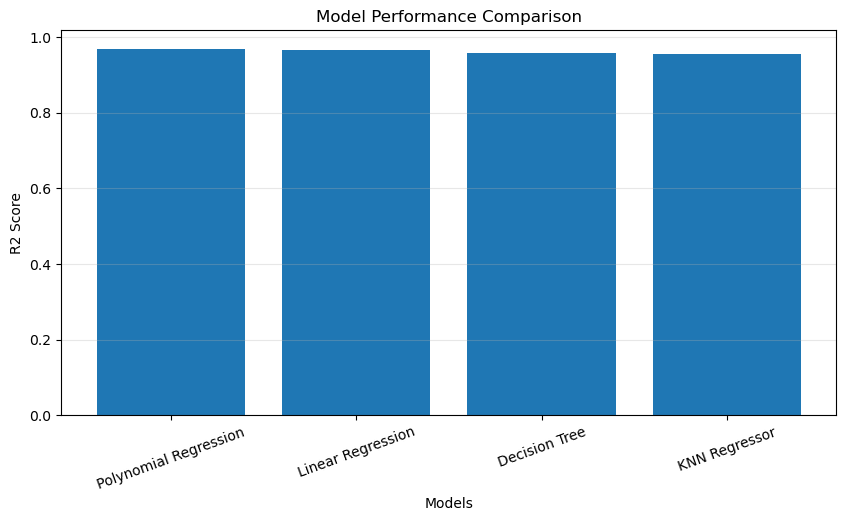

In [34]:
plt.figure(figsize=(10,5))

plt.bar(
    results_df['Model'],
    results_df['R2 Score']
)

plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.title("Model Performance Comparison")

plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)

plt.show()

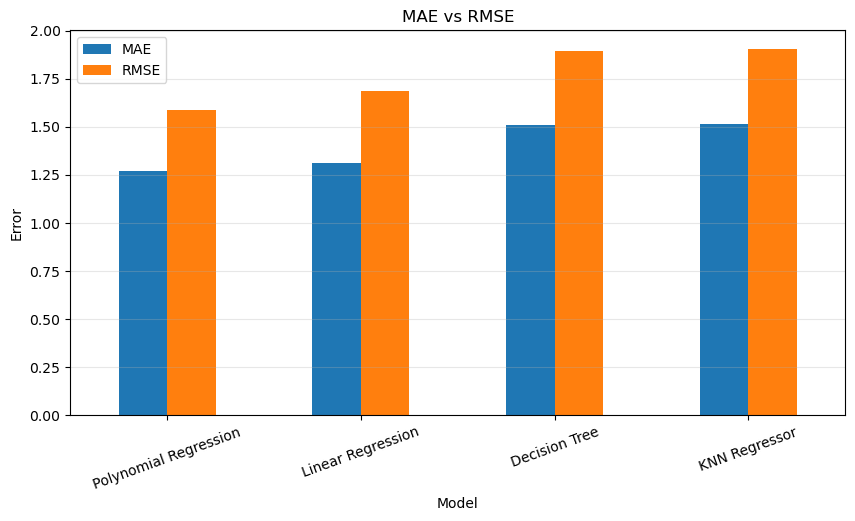

In [35]:
results_df.set_index('Model')[['MAE', 'RMSE']].plot(
    kind='bar',
    figsize=(10,5)
)

plt.title("MAE vs RMSE")
plt.ylabel("Error")
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [46]:
# Select the best model name
best_model_name = results_df.loc[0, 'Model']

# Store the actual trained model objects
models = {
    'KNN Regressor': best_knn,
    'Decision Tree': best_dt,
    'Linear Regression': best_lr,
    'Polynomial Regression': best_poly
}

# Select the actual model object
best_model = models[best_model_name]

best_r2 = results_df.loc[0, 'R2 Score']

print("Best Model:", best_model_name)
print("Best R2 Score:", best_r2)
print("Best R2 Percentage:", best_r2 * 100, "%")
print("Model Object Type:", type(best_model))

Best Model: Polynomial Regression
Best R2 Score: 0.969481366994483
Best R2 Percentage: 96.9481366994483 %
Model Object Type: <class 'sklearn.pipeline.Pipeline'>


In [47]:
artifact = {
    'model': best_model,

    'feature_columns': X.columns.tolist(),

    'numeric_features': numeric_features,

    'categorical_features': categorical_features,

    'category_options': {
        col: X[col].dropna().unique().tolist()
        for col in categorical_features
    },

    'numeric_defaults': X[numeric_features].median().to_dict(),

    'numeric_min': X[numeric_features].min().to_dict(),

    'numeric_max': X[numeric_features].max().to_dict(),

    'target': 'diabetes_risk_score',

    'model_name': best_model_name
}

joblib.dump(artifact, 'bestest_diabetes_model.pkl')

print("Model saved successfully!")
print("Saved model type:", type(artifact['model']))

Model saved successfully!
Saved model type: <class 'sklearn.pipeline.Pipeline'>


In [48]:

loaded_artifact = joblib.load('bestest_diabetes_model.pkl')

loaded_model = loaded_artifact['model']

print("Loaded Model Type:", type(loaded_model))

sample = x_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Actual Value:", y_test.iloc[0])
print("Predicted Value:", prediction[0])

Loaded Model Type: <class 'sklearn.pipeline.Pipeline'>
Actual Value: 29.2
Predicted Value: 29.489296816897724


In [2]:
import sklearn
print(sklearn.__version__)

1.7.2


In [3]:
python -m pip install scikit-learn==1.9.1

SyntaxError: invalid syntax (1644354025.py, line 1)